# Deteksi Pneumonia dari Chest X-Ray (DenseNet121 / EfficientNetB0)

## 0. Setup

In [66]:
import os, re, sys, json, glob, time, hashlib
from datetime import date
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import sklearn, tensorflow as tf, keras
from keras import layers
from PIL import Image
from sklearn import metrics as skm
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.utils.class_weight import compute_class_weight

print('python', sys.version.split()[0], '| tensorflow', tf.__version__, '| keras', keras.__version__,
      '| scikit-learn', sklearn.__version__, '| backend', keras.backend.backend())

BASE = dict(seed=42, img=224, batch=32, backbone='densenet121', class_weight=True, flip=True,
            dropout=0.3, l2=1e-4, lr_a=1e-3, epochs_a=10, lr_b=1e-4, epochs_b=30, unfreeze_n=50, stage_b=True)
EXPERIMENTS = {                                   # tiap eksperimen mengubah satu variabel dari E2
    'T0_budget':              dict(epochs_a=1, stage_b=False),   # ukur waktu 1 epoch (PRD Bagian 8)
    'E1_densenet121_stageA':  dict(stage_b=False),
    'E2_densenet121':         dict(),
    'E3_efficientnetb0':      dict(backbone='efficientnetb0'),
    'E4_densenet121_no_cw':   dict(class_weight=False),
    'E5_densenet121_no_flip': dict(flip=False),
    'E6_resnet50':            dict(backbone='resnet50'),
}
EXP = 'E2_densenet121'                            # <-- ganti per run
CONFIG = {**BASE, **EXPERIMENTS[EXP]}
SEED, IMG, BATCH = CONFIG['seed'], CONFIG['img'], CONFIG['batch']

keras.utils.set_random_seed(SEED)
if tf.config.list_physical_devices('GPU'):
    keras.mixed_precision.set_global_policy('mixed_float16')
print('GPU:', tf.config.list_physical_devices('GPU'), '| policy:', keras.mixed_precision.global_policy().name)

WORK = Path('/kaggle/working/outputs')
OUT = WORK / EXP
(OUT / 'figs').mkdir(parents=True, exist_ok=True)
json.dump(CONFIG, open(OUT / 'config.json', 'w'), indent=2)
print(EXP, CONFIG)

python 3.13.16 | tensorflow 2.21.0 | keras 3.13.2 | scikit-learn 1.6.1 | backend tensorflow
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')] | policy: mixed_float16
E2_densenet121 {'seed': 42, 'img': 224, 'batch': 32, 'backbone': 'densenet121', 'class_weight': True, 'flip': True, 'dropout': 0.3, 'l2': 0.0001, 'lr_a': 0.001, 'epochs_a': 10, 'lr_b': 0.0001, 'epochs_b': 30, 'unfreeze_n': 50, 'stage_b': True}


## 1. Inventaris data dan EDA

In [67]:
roots = [p for p in glob.glob('/kaggle/input/**/chest_xray', recursive=True)
         if '__MACOSX' not in p and os.path.isdir(f'{p}/train')]
assert roots, 'Dataset belum ditambahkan: Add Input -> chest-xray-pneumonia'
ROOT = min(roots, key=len)                        # dataset punya salinan ter-nest, ambil yang teratas
print('ROOT =', ROOT)

df = pd.DataFrame([dict(path=f'{o}/{c}/{f}', label=int(c == 'PNEUMONIA'), origin=o)
                   for o in ['train', 'val', 'test'] for c in ['NORMAL', 'PNEUMONIA']
                   for f in sorted(os.listdir(f'{ROOT}/{o}/{c}'))
                   if not f.startswith('.') and f.lower().endswith(('.jpeg', '.jpg', '.png'))])
print(df.groupby(['origin', 'label']).size().unstack().rename(columns={0: 'NORMAL', 1: 'PNEUMONIA'}))
assert df.origin.value_counts().to_dict() == {'train': 5216, 'test': 624, 'val': 16}, 'Jumlah file beda dari A1: STOP'

ROOT = /kaggle/input/datasets/paultimothymooney/chest-xray-pneumonia/chest_xray
label   NORMAL  PNEUMONIA
origin                   
test       234        390
train     1341       3875
val          8          8


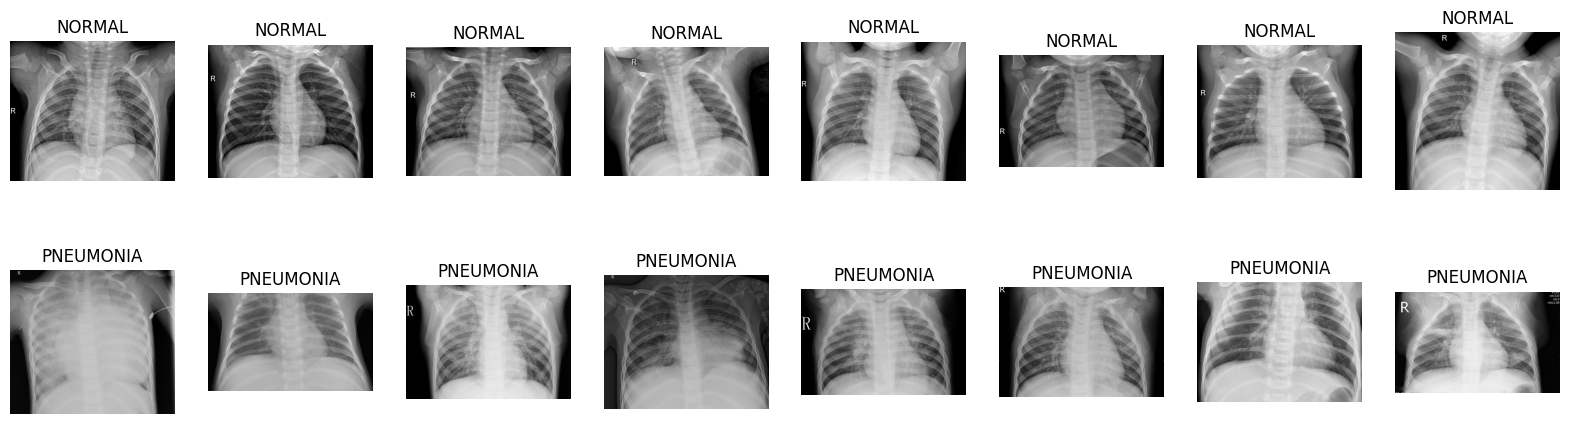

Ukuran gambar asli:
       lebar  tinggi
min   384.0   127.0
50%  1281.0   888.0
max  2916.0  2713.0


In [68]:
fig, ax = plt.subplots(2, 8, figsize=(20, 5.5))
for r, lab in enumerate([0, 1]):
    for a, p in zip(ax[r], df[(df.origin == 'train') & (df.label == lab)].sample(8, random_state=SEED).path):
        a.imshow(Image.open(f'{ROOT}/{p}'), cmap='gray'); a.set_title(['NORMAL', 'PNEUMONIA'][lab]); a.axis('off')
plt.show()

sizes = pd.DataFrame([Image.open(f'{ROOT}/{p}').size for p in df.path], columns=['lebar', 'tinggi'])
print('Ukuran gambar asli:\n', sizes.describe().loc[['min', '50%', 'max']])

## 2. Split per pasien → `split.csv`

In [69]:
def patient_id(path, label):
    m = re.search(r'person([0-9]+)_' if label == 1 else r'IM-([0-9]+)-', os.path.basename(path))
    return f'{label}_{m.group(1)}' if m else None

df['group'] = [patient_id(p, y) for p, y in zip(df.path, df.label)]
print('Gagal parse ID pasien:', df.group.isna().sum())
df['group'] = df.group.fillna(df.label.astype(str) + '_' + df.path.map(os.path.basename))  # gagal parse: 1 file = 1 grup

# A3 gagal: ID yang sama muncul di train/val bawaan dan test. Nama file tidak bisa membedakan "pasien sama"
# dari "nomor dipakai ulang", jadi pilih yang aman: buang gambar train/val bawaan dengan ID itu. Test tidak diubah.
overlap = set(df[df.origin != 'test'].group) & set(df[df.origin == 'test'].group)
drop = (df.origin != 'test') & df.group.isin(overlap)
print(f'ID beririsan dengan test: {len(overlap)} (NORMAL {sum(x[0] == "0" for x in overlap)}, '
      f'PNEUMONIA {sum(x[0] == "1" for x in overlap)})')
print(f'Gambar train/val bawaan dibuang: {drop.sum()} dari {(df.origin != "test").sum()}')
ex = sorted(overlap)[:2] + sorted(overlap)[-2:]
print(df[df.group.isin(ex)].sort_values('group')[['group', 'path']].to_string(index=False))  # contoh file yang bentrok
df = df[~drop].reset_index(drop=True)

trval = df[df.origin != 'test'].reset_index(drop=True)
_, va_idx = next(StratifiedGroupKFold(n_splits=7, shuffle=True, random_state=SEED).split(trval, trval.label, trval.group))
trval['split'] = 'train'
trval.loc[va_idx, 'split'] = 'val'
split = pd.concat([trval, df[df.origin == 'test'].assign(split='test')], ignore_index=True)[['path', 'label', 'group', 'split']]
split.to_csv(WORK / 'split.csv', index=False)     # path relatif terhadap ROOT
SPLIT_MD5 = hashlib.md5((WORK / 'split.csv').read_bytes()).hexdigest()[:8]

g = {s: set(split.group[split.split == s]) for s in ['train', 'val', 'test']}
assert not (g['train'] & g['val'] or g['train'] & g['test'] or g['val'] & g['test']), 'Ada pasien di dua split'
print(split.groupby(['split', 'label']).size().unstack().rename(columns={0: 'NORMAL', 1: 'PNEUMONIA'}))
print('split.csv md5:', SPLIT_MD5, '(harus sama di semua eksperimen)')

Gagal parse ID pasien: 0
ID beririsan dengan test: 264 (NORMAL 94, PNEUMONIA 170)
Gambar train/val bawaan dibuang: 551 dari 5232
 group                                      path
0_0117            train/NORMAL/IM-0117-0001.jpeg
0_0117     test/NORMAL/NORMAL2-IM-0117-0001.jpeg
0_0129            train/NORMAL/IM-0129-0001.jpeg
0_0129     test/NORMAL/NORMAL2-IM-0129-0001.jpeg
  1_97   train/PNEUMONIA/person97_virus_180.jpeg
  1_97   train/PNEUMONIA/person97_virus_181.jpeg
  1_97 test/PNEUMONIA/person97_bacteria_468.jpeg
  1_99   train/PNEUMONIA/person99_virus_183.jpeg
  1_99 test/PNEUMONIA/person99_bacteria_473.jpeg
  1_99 test/PNEUMONIA/person99_bacteria_474.jpeg
label  NORMAL  PNEUMONIA
split                   
test      234        390
train    1086       2932
val       169        494
split.csv md5: 18f95e62 (harus sama di semua eksperimen)


## 3. Pipeline tf.data

In [70]:
AUTOTUNE = tf.data.AUTOTUNE

def load(path, label):
    img = tf.io.decode_jpeg(tf.io.read_file(path), channels=3)         # grayscale -> RGB
    img = tf.image.resize(img, (IMG, IMG), antialias=True)
    img = tf.cast(tf.clip_by_value(tf.round(img), 0, 255), tf.uint8)   # cache sebagai uint8
    return img, tf.reshape(tf.cast(label, tf.float32), [1])             # label (1,) -> batch (B, 1)

def make_ds(d, train):
    ds = tf.data.Dataset.from_tensor_slices(((ROOT + '/' + d.path).values, d.label.values))
    ds = ds.map(load, num_parallel_calls=AUTOTUNE).cache()
    if train:
        ds = ds.shuffle(2048, seed=SEED)
    ds = ds.batch(BATCH).map(lambda x, y: (tf.cast(x, tf.float32), y), num_parallel_calls=AUTOTUNE)
    return ds.prefetch(AUTOTUNE)

train_df, val_df, test_df = (split[split.split == s].reset_index(drop=True) for s in ['train', 'val', 'test'])
train_ds, val_ds, test_ds = make_ds(train_df, True), make_ds(val_df, False), make_ds(test_df, False)

## 4. Model dan uji preprocessing

In [71]:
def preprocessing_block(backbone):
    if backbone == 'densenet121':                 # setara mode 'torch' di densenet.preprocess_input
        return keras.Sequential([layers.Rescaling(1 / 255.),
                                 layers.Normalization(mean=[0.485, 0.456, 0.406],
                                                      variance=[0.229 ** 2, 0.224 ** 2, 0.225 ** 2])], name='preprocess')
    if backbone == 'resnet50':                    # mode 'caffe': RGB -> BGR lalu kurangi mean ImageNet
        return keras.Sequential([layers.Lambda(keras.applications.resnet50.preprocess_input)], name='preprocess')
    return keras.Sequential([layers.Identity()], name='preprocess')   # EfficientNet: normalisasi ada di dalam model

def build_model(backbone='densenet121', dropout=0.3, l2=1e-4, flip=True):
    kw = dict(include_top=False, weights='imagenet', input_shape=(IMG, IMG, 3))
    base = {'densenet121': keras.applications.DenseNet121, 'efficientnetb0': keras.applications.EfficientNetB0,
            'resnet50': keras.applications.ResNet50}[backbone](**kw)
    base.trainable = False
    aug = [layers.RandomRotation(0.04), layers.RandomZoom(0.15), layers.RandomTranslation(0.1, 0.1), layers.RandomContrast(0.1)]
    if flip:
        aug.append(layers.RandomFlip('horizontal'))
    inputs = keras.Input((IMG, IMG, 3))                    # float32, nilai 0-255
    x = keras.Sequential(aug, name='augment')(inputs)      # aktif hanya saat training
    x = preprocessing_block(backbone)(x)
    x = base(x, training=False)                            # BatchNorm tetap mode inference
    x = layers.GlobalAveragePooling2D(name='gap')(x)
    x = layers.Dense(256, activation='relu', name='fc', kernel_regularizer=keras.regularizers.l2(l2))(x)
    x = layers.Dropout(dropout, name='drop')(x)
    out = layers.Dense(1, activation='sigmoid', dtype='float32', name='out')(x)
    return keras.Model(inputs, out), base

def unfreeze_top(base, n):
    base.trainable = True
    for l in base.layers[:-n]:
        l.trainable = False
    for l in base.layers:
        if isinstance(l, layers.BatchNormalization):
            l.trainable = False

In [72]:
x = np.random.default_rng(SEED).uniform(0, 255, (2, IMG, IMG, 3)).astype('float32')
ref = keras.applications.densenet.preprocess_input(x.copy())
assert np.allclose(preprocessing_block('densenet121')(x), ref, atol=1e-2), 'Preprocessing DenseNet salah'  # atol: float16
assert np.array_equal(keras.applications.efficientnet.preprocess_input(x.copy()), x), 'EfficientNet butuh preprocess'
assert np.allclose(preprocessing_block('resnet50')(x), keras.applications.resnet50.preprocess_input(x.copy()), atol=0.5), 'Preprocessing ResNet salah'  # skala ±150, float16
print('Uji preprocessing lolos')

model, base = build_model(CONFIG['backbone'], CONFIG['dropout'], CONFIG['l2'], CONFIG['flip'])
model.summary()

Uji preprocessing lolos


Model: "functional_29"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_33 (InputLayer)     │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augment (Sequential)            │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ preprocess (Sequential)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ densenet121 (Functional)        │ (None, 7, 7, 1024)     │     7,037,504 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gap (GlobalAveragePooling2D)    │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ fc (Dense)                      │ (None, 256)            │       262,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ drop (Dropout)                  │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ out (Dense)                     │ (None, 1)              │           257 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 7,300,161 (27.85 MB)

 Trainable params: 262,657 (1.00 MB)

 Non-trainable params: 7,037,504 (26.85 MB)

## 5. Training dua tahap
Tahap A: backbone beku, latih head. Tahap B: buka `unfreeze_n` layer teratas (BatchNorm tetap beku), CosineDecay.

In [73]:
def run_experiment(cfg):
    cw = compute_class_weight('balanced', classes=np.array([0, 1]), y=train_df.label.values)
    class_weight = {0: cw[0], 1: cw[1]} if cfg['class_weight'] else None
    metrics = lambda: ['accuracy', keras.metrics.AUC(name='auc'),
                       keras.metrics.Recall(name='recall'), keras.metrics.Precision(name='precision')]
    logs = lambda: [keras.callbacks.ModelCheckpoint(OUT / 'best.keras', monitor='val_loss', save_best_only=True),
                    keras.callbacks.CSVLogger(OUT / 'history.csv', append=True)]

    model.compile(keras.optimizers.Adam(cfg['lr_a']), 'binary_crossentropy', metrics=metrics())
    model.fit(train_ds, validation_data=val_ds, epochs=cfg['epochs_a'], class_weight=class_weight,
              callbacks=[keras.callbacks.EarlyStopping('val_loss', patience=3, restore_best_weights=True), *logs()])
    if not cfg['stage_b']:
        return
    unfreeze_top(base, cfg['unfreeze_n'])
    sched = keras.optimizers.schedules.CosineDecay(cfg['lr_b'], decay_steps=cfg['epochs_b'] * len(train_ds), alpha=0.01)
    model.compile(keras.optimizers.Adam(sched), 'binary_crossentropy', metrics=metrics())   # wajib compile ulang
    model.fit(train_ds, validation_data=val_ds, epochs=cfg['epochs_b'], class_weight=class_weight,
              callbacks=[keras.callbacks.EarlyStopping('val_loss', patience=5, restore_best_weights=True), *logs()])

t0 = time.time()
run_experiment(CONFIG)
TRAIN_MIN = (time.time() - t0) / 60
print(f'Waktu training: {TRAIN_MIN:.1f} menit')

Epoch 1/10
126/126 ━━━━━━━━━━━━━━━━━━━━ 57s 220ms/step - accuracy: 0.8514 - auc: 0.9335 - loss: 0.3523 - precision: 0.9424 - recall: 0.8482 - val_accuracy: 0.9487 - val_auc: 0.9901 - val_loss: 0.1814 - val_precision: 0.9915 - val_recall: 0.9393
Epoch 2/10
126/126 ━━━━━━━━━━━━━━━━━━━━ 18s 141ms/step - accuracy: 0.9318 - auc: 0.9787 - loss: 0.2032 - precision: 0.9763 - recall: 0.9291 - val_accuracy: 0.9336 - val_auc: 0.9932 - val_loss: 0.1879 - val_precision: 0.9978 - val_recall: 0.9130
Epoch 3/10
126/126 ━━━━━━━━━━━━━━━━━━━━ 19s 153ms/step - accuracy: 0.9348 - auc: 0.9847 - loss: 0.1744 - precision: 0.9795 - recall: 0.9301 - val_accuracy: 0.9563 - val_auc: 0.9941 - val_loss: 0.1477 - val_precision: 0.9979 - val_recall: 0.9433
Epoch 4/10
126/126 ━━━━━━━━━━━━━━━━━━━━ 18s 140ms/step - accuracy: 0.9370 - auc: 0.9826 - loss: 0.1824 - precision: 0.9789 - recall: 0.9338 - val_accuracy: 0.9487 - val_auc: 0.9934 - val_loss: 0.1710 - val_precision: 0.9978 - val_recall: 0.9332
Epoch 5/10
126/126 ━

## 6. Evaluasi
Threshold dipilih dari **val** (target recall 0,95), dikunci, lalu test diprediksi **sekali**.

In [74]:
def pick_threshold(y, p, target_recall=0.95):
    fpr, tpr, thr = skm.roc_curve(y, p)
    return float(thr[np.where(tpr >= target_recall)[0][0]])   # titik pertama yang mencapai target = specificity tertinggi

def predict(d, ds):
    return d.assign(y_true=d.label, y_prob=model.predict(ds, verbose=0).ravel())[['path', 'group', 'y_true', 'y_prob']]

def rec_spec_auc(y, p, yhat):
    return dict(recall=skm.recall_score(y, yhat), specificity=skm.recall_score(y, yhat, pos_label=0),
                auc=skm.roc_auc_score(y, p))

def fmt(m, k):
    return f"{m[k]:.3f} [{m['ci95'][k][0]:.3f}–{m['ci95'][k][1]:.3f}]"

val_preds = predict(val_df, val_ds)
THR = pick_threshold(val_preds.y_true, val_preds.y_prob)
test_preds = predict(test_df, test_ds)
test_preds['y_pred'] = (test_preds.y_prob >= THR).astype(int)
val_preds.to_csv(OUT / 'val_preds.csv', index=False)
test_preds.to_csv(OUT / 'test_preds.csv', index=False)

y, p, yhat = test_preds.y_true.values, test_preds.y_prob.values, test_preds.y_pred.values
m = dict(threshold=THR, **rec_spec_auc(y, p, yhat), precision=skm.precision_score(y, yhat, zero_division=0),
         f1=skm.f1_score(y, yhat), accuracy=skm.accuracy_score(y, yhat), pr_auc=skm.average_precision_score(y, p),
         train_minutes=round(TRAIN_MIN, 1))
rng = np.random.default_rng(SEED)
boot = pd.DataFrame([rec_spec_auc(y[i], p[i], yhat[i]) for i in (rng.integers(0, len(y), len(y)) for _ in range(1000))])
m['ci95'] = {k: boot[k].quantile([0.025, 0.975]).tolist() for k in boot}
json.dump(m, open(OUT / 'metrics.json', 'w'), indent=2)
print(json.dumps(m, indent=2))

{
  "threshold": 0.6372600197792053,
  "recall": 0.9743589743589743,
  "specificity": 0.7222222222222222,
  "auc": 0.9667378917378917,
  "precision": 0.8539325842696629,
  "f1": 0.9101796407185628,
  "accuracy": 0.8798076923076923,
  "pr_auc": 0.9760614775295536,
  "train_minutes": 6.0,
  "ci95": {
    "recall": [
      0.9584352078239609,
      0.9876275448449491
    ],
    "specificity": [
      0.6622792397660818,
      0.7791808920704846
    ],
    "auc": [
      0.9516619079215406,
      0.9790244402823766
    ]
  }
}


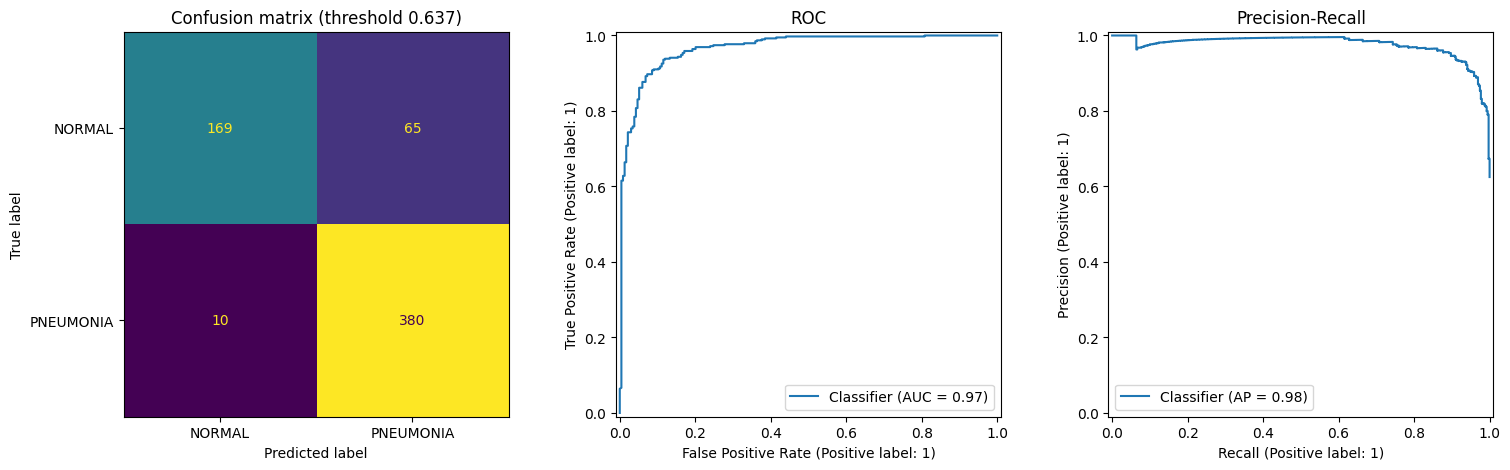

Tempel ke tabel Hasil di EXPERIMENTS.md:
| E2_densenet121 | 2026-11-05 | — (referensi) | 0.974 [0.958–0.988] | 0.722 [0.662–0.779] | 0.967 [0.952–0.979] | 0.637 | 18f95e62 | 6 | v? |


In [75]:
fig, ax = plt.subplots(1, 3, figsize=(18, 5))
skm.ConfusionMatrixDisplay.from_predictions(y, yhat, display_labels=['NORMAL', 'PNEUMONIA'], ax=ax[0], colorbar=False)
skm.RocCurveDisplay.from_predictions(y, p, ax=ax[1])
skm.PrecisionRecallDisplay.from_predictions(y, p, ax=ax[2])
ax[0].set_title(f'Confusion matrix (threshold {THR:.3f})'); ax[1].set_title('ROC'); ax[2].set_title('Precision-Recall')
fig.savefig(OUT / 'figs/eval.png', dpi=120, bbox_inches='tight'); plt.show()

change = ', '.join(f'{k}={v}' for k, v in EXPERIMENTS[EXP].items()) or '— (referensi)'
print('Tempel ke tabel Hasil di EXPERIMENTS.md:')
print(f"| {EXP} | {date.today()} | {change} | {fmt(m, 'recall')} | {fmt(m, 'specificity')} | {fmt(m, 'auc')} "
      f"| {THR:.3f} | {SPLIT_MD5} | {TRAIN_MIN:.0f} | v? |")

## 7. Grad-CAM (8 contoh TP, TN, FP, FN dari test)
Angka di judul tiap gambar = **confidence score** `p(pneumonia)` dari model; diprediksi PNEUMONIA bila `p ≥ threshold`.

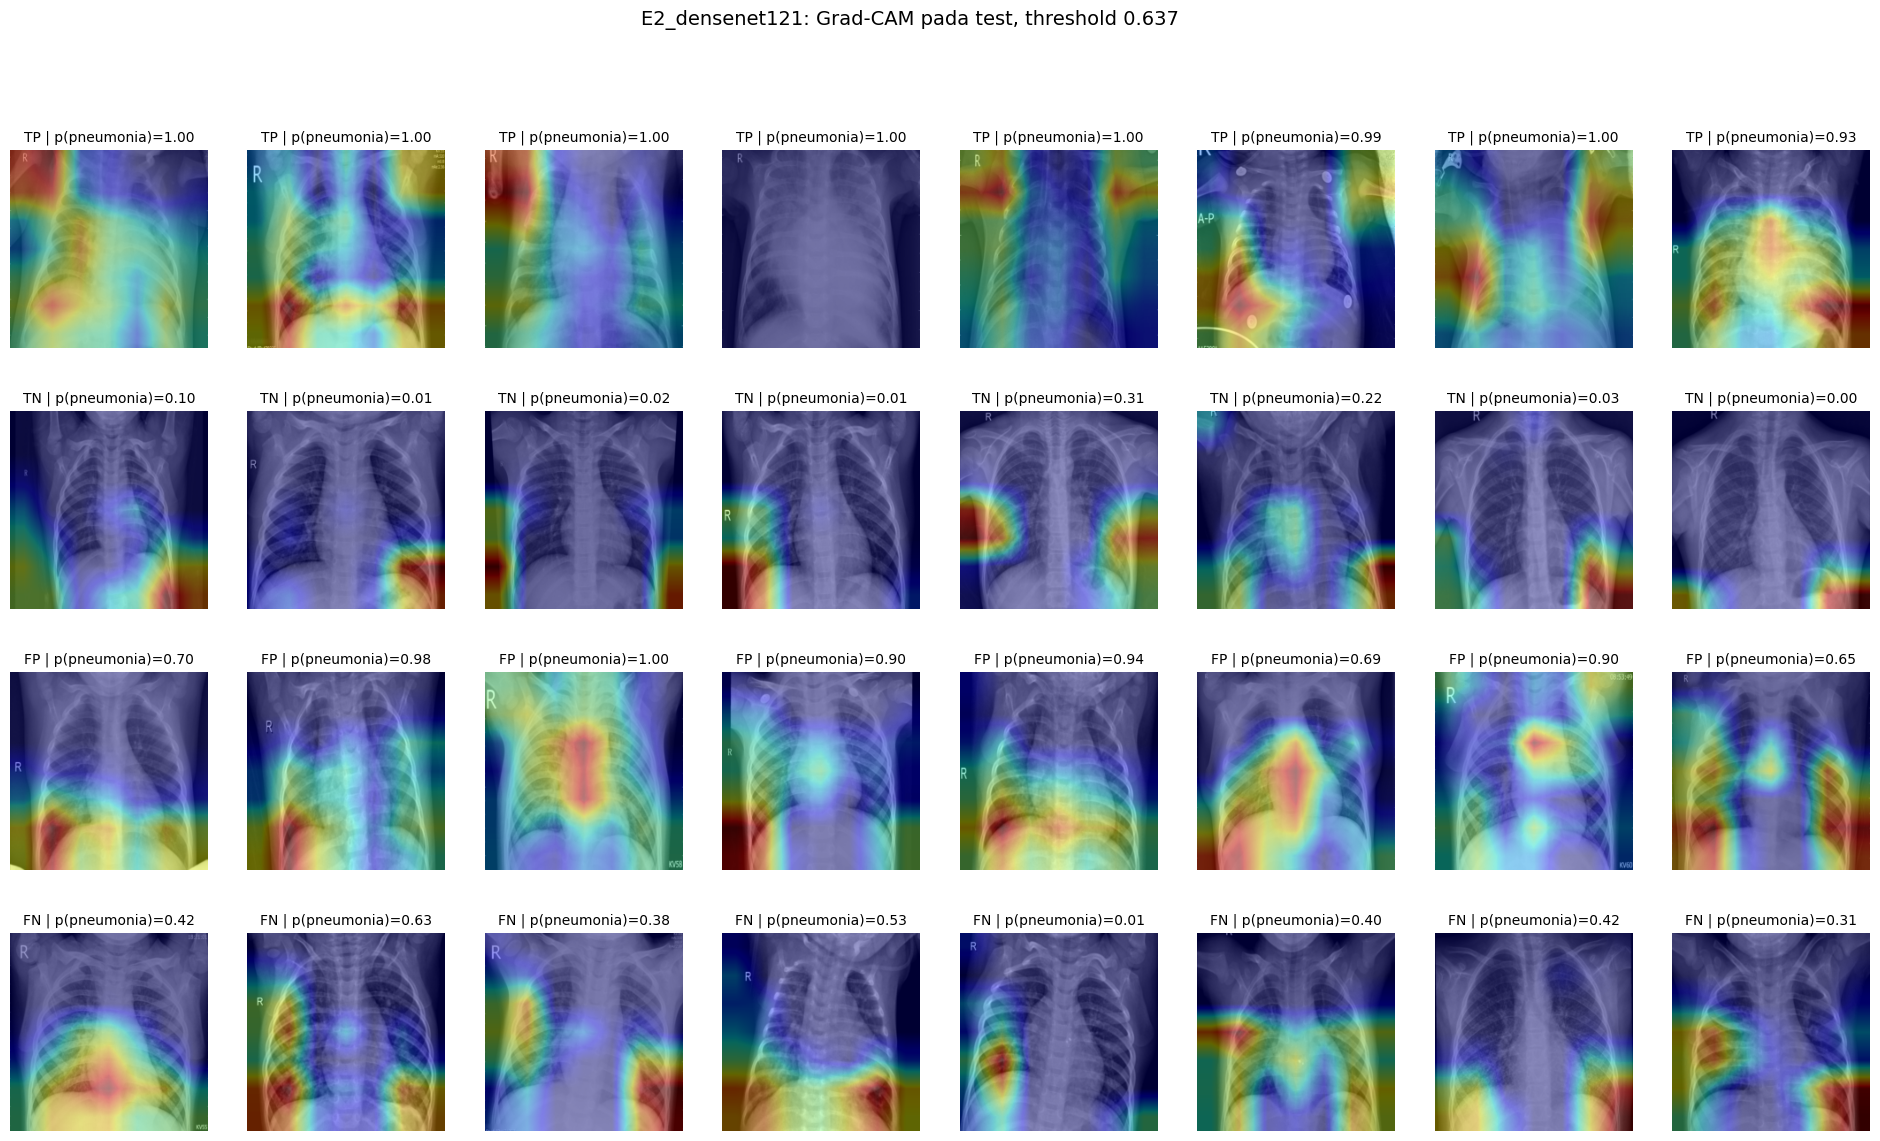

In [76]:
def gradcam(img):                                          # img: (224, 224, 3) float 0-255
    x = model.get_layer('preprocess')(img[None])
    fmap = tf.cast(base(x, training=False), tf.float32)    # ekstraktor fitur = output backbone
    with tf.GradientTape() as tape:
        tape.watch(fmap)
        h = fmap
        for name in ['gap', 'fc', 'drop', 'out']:          # head
            h = model.get_layer(name)(h)
    w = tf.reduce_mean(tape.gradient(h, fmap), axis=(1, 2))
    cam = tf.nn.relu(tf.reduce_sum(fmap * w[:, None, None, :], axis=-1))[0]
    cam = tf.image.resize((cam / (tf.reduce_max(cam) + 1e-8))[..., None], (IMG, IMG))[..., 0]
    return cam.numpy(), float(h[0, 0])

case = np.select([(y == 1) & (yhat == 1), (y == 0) & (yhat == 0), (y == 0) & (yhat == 1)], ['TP', 'TN', 'FP'], 'FN')
fig, ax = plt.subplots(4, 8, figsize=(24, 13))
for r, c in enumerate(['TP', 'TN', 'FP', 'FN']):
    idx = np.where(case == c)[0]
    if len(idx) == 0:
        ax[r][0].set_title(f'{c}: tidak ada contoh', fontsize=10)
    for a, i in zip(ax[r], rng.choice(idx, min(8, len(idx)), replace=False)):
        img = load(ROOT + '/' + test_df.path[i], 0)[0].numpy().astype('float32')
        cam, _ = gradcam(img)
        a.imshow(img.astype('uint8')); a.imshow(cam, cmap='jet', alpha=0.4)
        a.set_title(f'{c} | p(pneumonia)={p[i]:.2f}', fontsize=10)
    for a in ax[r]:
        a.axis('off')
fig.suptitle(f'{EXP}: Grad-CAM pada test, threshold {THR:.3f}', fontsize=14)
fig.savefig(OUT / 'figs/gradcam.png', dpi=100, bbox_inches='tight'); plt.show()

Catat di `EXPERIMENTS.md`: sorotan jatuh di area paru atau di artefak (teks, marker, tepi citra)?

## 8. Rekap semua eksperimen
Agar hasil versi sebelumnya ikut terbaca: **Add Input → Your Work → Notebooks →** pilih notebook ini (output-nya ter-mount di `/kaggle/input`).

In [77]:
def recap_row(f):
    r = json.load(open(f))
    return {'exp': Path(f).parent.name, **{k: fmt(r, k) for k in ['recall', 'specificity', 'auc']}, 'threshold': round(r['threshold'], 3)}

found = glob.glob('/kaggle/input/**/metrics.json', recursive=True) + glob.glob(f'{WORK}/*/metrics.json')
display(pd.DataFrame([recap_row(f) for f in found]).drop_duplicates('exp', keep='last').sort_values('exp'))

,exp,recall,specificity,auc,threshold
3,E1_densenet121_stageA,0.969 [0.951–0.984],0.718 [0.657–0.779],0.962 [0.946–0.976],0.893
0,E2_densenet121,0.974 [0.958–0.988],0.722 [0.662–0.779],0.967 [0.952–0.979],0.637
2,E3_efficientnetb0,0.990 [0.979–0.998],0.662 [0.599–0.722],0.964 [0.949–0.977],0.803
4,E4_densenet121_no_cw,0.969 [0.950–0.985],0.825 [0.775–0.873],0.973 [0.958–0.984],0.977
5,E5_densenet121_no_flip,0.987 [0.974–0.997],0.782 [0.728–0.834],0.970 [0.955–0.982],0.929
1,E6_resnet50,0.982 [0.968–0.995],0.765 [0.707–0.818],0.977 [0.963–0.987],0.882


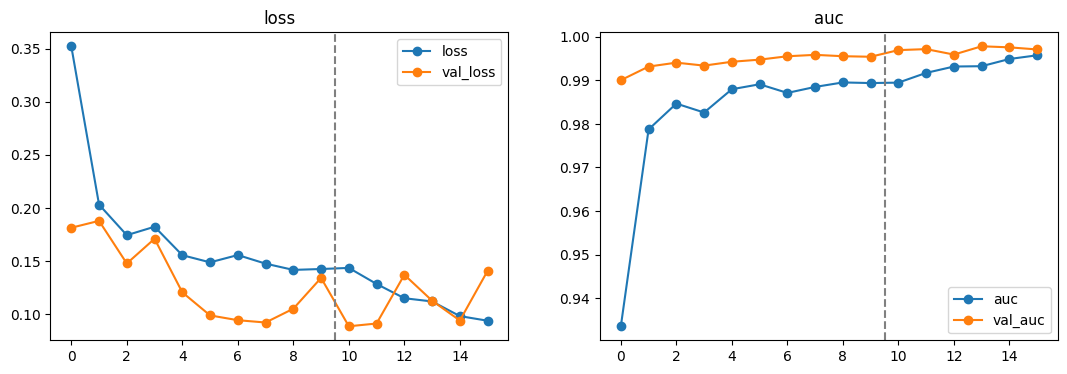

,val,test
recall,0.966,0.974
specificity,1.000,0.722
auc,0.997,0.967


In [78]:
h = pd.read_csv(OUT / 'history.csv')
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for a, k in zip(ax, ['loss', 'auc']):
    h[[k, f'val_{k}']].plot(ax=a, title=k, marker='o')
    for b in h.index[h.epoch == 0][1:]:
        a.axvline(b - 0.5, ls='--', c='gray')          # garis putus = mulai Tahap B
plt.show()

vy, vp = val_preds.y_true.values, val_preds.y_prob.values
display(pd.DataFrame({'val': rec_spec_auc(vy, vp, (vp >= THR).astype(int)), 'test': rec_spec_auc(y, p, yhat)}).round(3))